# Project 3
**Name:** Gemma Williams

**Student Number:** 48843674

**Data sourced from:** https://www.kaggle.com/datasets/anthonypino/melbourne-housing-market?select=Melbourne_housing_FULL.csv

In [76]:
using Pkg
Pkg.activate(".")
Pkg.instantiate()

include("housing_data.jl") # Load in housing data and makes necessary transformations
#(can take a few minutes to run)


  Activating project at `c:\Users\gemma\UNI\MATH2504\MATH2504 Assessment\Gemma-Williams-2504-2025-PROJECT3`


Row,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,Year,Month,Latitude,Longitude,Age
,String31,String31,Int64,String1,Float64,String3,String31,String15,Float64,String7,Int64,Int64,Int64,Int64,Float64,Int64,String31,String15,String15,String31,Int64,Int64,Int64,Float64,Float64,Int64
1,Abbotsford,68 Studley St,2,h,0.0,SS,Jellis,3/09/2016,2.5,3067,2,1,1,126,0.0,0,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019,2016,9,-37.8014,144.996,0
2,Abbotsford,85 Turner St,2,h,1.48,S,Biggin,3/12/2016,2.5,3067,2,1,1,202,0.0,0,Yarra City Council,-37.7996,144.9984,Northern Metropolitan,4019,2016,12,-37.7996,144.998,0
3,Abbotsford,25 Bloomburg St,2,h,1.035,S,Biggin,4/02/2016,2.5,3067,2,1,0,156,79.0,1900,Yarra City Council,-37.8079,144.9934,Northern Metropolitan,4019,2016,2,-37.8079,144.993,116
4,Abbotsford,18/659 Victoria St,3,u,0.0,VB,Rounds,4/02/2016,2.5,3067,3,2,1,0,0.0,0,Yarra City Council,-37.8114,145.0116,Northern Metropolitan,4019,2016,2,-37.8114,145.012,0
5,Abbotsford,5 Charles St,3,h,1.465,SP,Biggin,4/03/2017,2.5,3067,3,2,0,134,150.0,1900,Yarra City Council,-37.8093,144.9944,Northern Metropolitan,4019,2017,3,-37.8093,144.994,117
6,Abbotsford,40 Federation La,3,h,0.85,PI,Biggin,4/03/2017,2.5,3067,3,2,1,94,0.0,0,Yarra City Council,-37.7969,144.9969,Northern Metropolitan,4019,2017,3,-37.7969,144.997,0
7,Abbotsford,55a Park St,4,h,1.6,VB,Nelson,4/06/2016,2.5,3067,3,1,2,120,142.0,2014,Yarra City Council,-37.8072,144.9941,Northern Metropolitan,4019,2016,6,-37.8072,144.994,2
8,Abbotsford,16 Maugie St,4,h,0.0,SN,Nelson,6/08/2016,2.5,3067,3,2,2,400,220.0,2006,Yarra City Council,-37.7965,144.9965,Northern Metropolitan,4019,2016,8,-37.7965,144.996,10
9,Abbotsford,53 Turner St,2,h,0.0,S,Biggin,6/08/2016,2.5,3067,4,1,2,201,0.0,1900,Yarra City Council,-37.7995,144.9974,Northern Metropolitan,4019,2016,8,-37.7995,144.997,116


## Task 1 Exploratory data of a single variable

Create several summaries and plots (e.g. histograms, or cumulative distributions, bar plots, ...) of the following variables: `Rooms`, `Price`, `Method`, `Distance`, and `Landsize`. Make sure to choose appropriate diagram types as different types of data require different types of plots.

### Rooms

Rooms summary statistics:
Summary Stats:
Length:         34857
Missing Count:  0
Mean:           3.031012
Std. Deviation: 0.969933
Minimum:        1.000000
1st Quartile:   2.000000
Median:         3.000000
3rd Quartile:   4.000000
Maximum:        16.000000



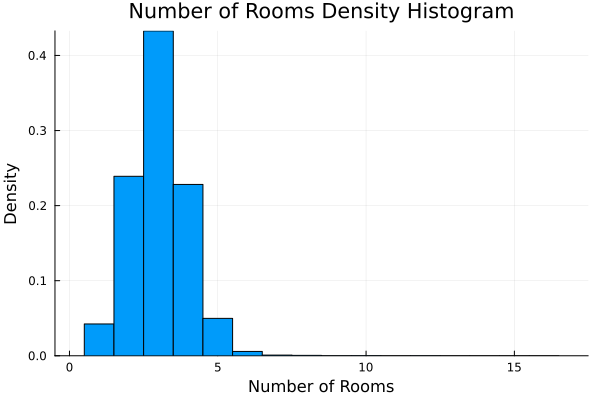

In [77]:
rooms_df = select(df, :Rooms)
filter!(row -> row.Rooms != 0, rooms_df)  # Remove rows where Rooms is 0 (missing)

summary_rooms = summarystats(rooms_df.Rooms)
println("Rooms summary statistics:")
println(summary_rooms)

histogram(rooms_df.Rooms, bins = minimum(rooms_df.Rooms)-0.5 : 1 : maximum(rooms_df.Rooms)+0.5,
    title = "Number of Rooms Density Histogram",
    xlabel = "Number of Rooms",
    ylabel = "Density",
    legend = false,
    normed = true)
savefig("task1_outputs/rooms_density_histogram.png")
display(plot!())


### Price

Price (m) summary statistics:
Summary Stats:
Length:         27247
Missing Count:  0
Mean:           1.050173
Std. Deviation: 0.641467
Minimum:        0.085000
1st Quartile:   0.635000
Median:         0.870000
3rd Quartile:   1.295000
Maximum:        11.200000



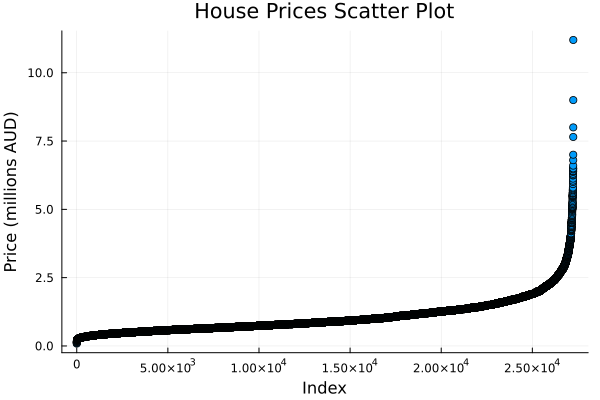

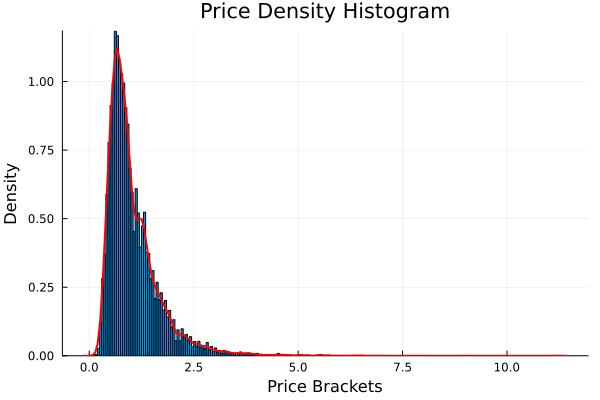

In [78]:
price_df = select(df, :Price)
filter!(row -> row.Price != 0, price_df)  # Remove rows where Price is 0 (missing)
sort!(price_df, :Price)

summary_price = summarystats(price_df.Price)
println("Price (m) summary statistics:")
println(summary_price)

scatter(1:length(price_df.Price), price_df.Price,
    title = "House Prices Scatter Plot",
    xlabel = "Index",
    ylabel = "Price (millions AUD)",
    legend = false)
savefig("task1_outputs/price_scatter_plot.png")
display(plot!())

histogram(price_df.Price, bins = :auto,
    title = "Price Density Histogram",
    xlabel = "Price Brackets",
    ylabel = "Density",
    legend = false,
    normed = true)
density!(price_df.Price, lw=2, lc=:red)
savefig("task1_outputs/price_density_histogram.png")
display(plot!())

**Visual analysis:**
- Some extreme outliers (very long tail to the right)
- Logarithmic transformation may be more appropriate for regression analysis (part 4)
- could include cumulative density but it is already pretty clear from the histogram

### Method

*From data description:*
- S - property sold;
- SP - property sold prior;
- PI - property passed in;
- PN - sold prior not disclosed;
- SN - sold not disclosed;
- NB - no bid;
- VB - vendor bid;
- W - withdrawn prior to auction;
- SA - sold after auction;
- SS - sold after auction price not disclosed.
- N/A - price or highest bid not available.

Method counts:
9×2 DataFrame
 Row │ Method   Count 
     │ String3  Int64 
─────┼────────────────
   1 │ SS          36
   2 │ S        19744
   3 │ VB        3108
   4 │ SP        5095
   5 │ PI        4850
   6 │ SN        1317
   7 │ W          173
   8 │ PN         308
   9 │ SA         226


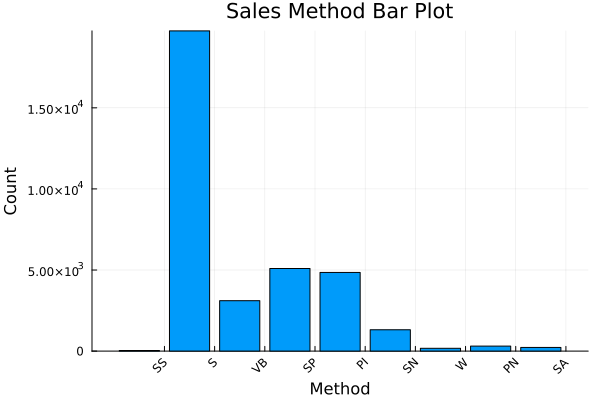

In [79]:
method_df = select(df, :Method)
# no filter needed as Method is qualitative and didn't have converted 0 values from missings

method_counts = combine(groupby(method_df, :Method), nrow => :Count)
println("Method counts:")
println(method_counts)

bar(method_counts.Method, method_counts.Count,
    title = "Sales Method Bar Plot",
    xlabel = "Method",
    ylabel = "Count",
    legend = false,
    xticks = (1:length(method_counts.Method), method_counts.Method),
    xrotation = 45)
savefig("task1_outputs/method_bar_plot.png")
display(plot!())

**Visual analysis:**
- Most common methods are S (sold) and PI (passed in)
- Some methods have very low counts (e.g., VB, W, SA, SS)
- May consider grouping less common methods together for analysis

### Distance

Distance summary statistics:
Summary Stats:
Length:         34779
Missing Count:  0
Mean:           11.209693
Std. Deviation: 6.775951
Minimum:        0.700000
1st Quartile:   6.400000
Median:         10.300000
3rd Quartile:   14.000000
Maximum:        48.100000



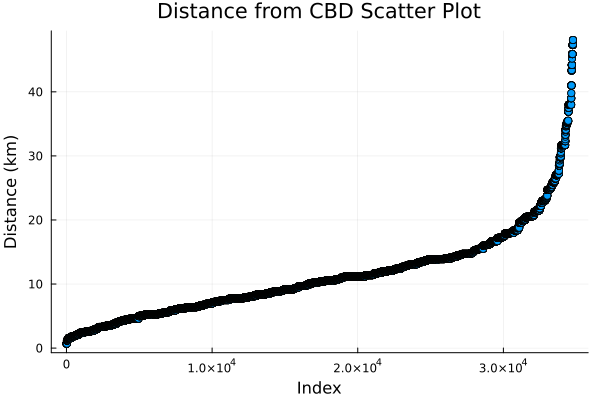

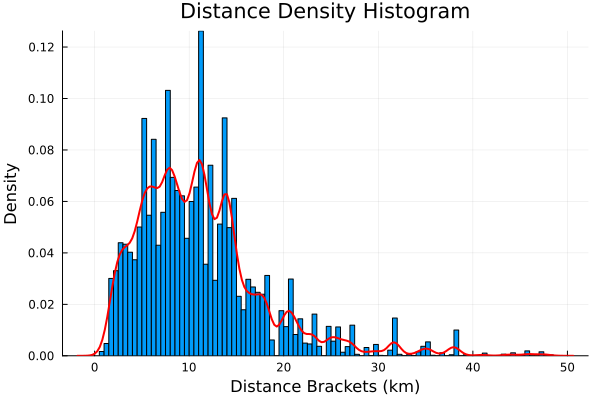

In [80]:
distance_df = select(df, :Distance)
filter!(row -> row.Distance != 0.0, distance_df)  # Remove rows where Distance is 0 (missing)
sort!(distance_df, :Distance)

summary_distance = summarystats(distance_df.Distance)
println("Distance summary statistics:")
println(summary_distance)

scatter(1:length(distance_df.Distance), distance_df.Distance,
    title = "Distance from CBD Scatter Plot",
    xlabel = "Index",
    ylabel = "Distance (km)",
    legend = false)
savefig("task1_outputs/distance_scatter_plot.png")
display(plot!())

histogram(distance_df.Distance, bins = :auto,
    title = "Distance Density Histogram",
    xlabel = "Distance Brackets (km)",
    ylabel = "Density",
    legend = false,
    normed = true)
density!(distance_df.Distance, lw=2, lc=:red)
savefig("task1_outputs/distance_density_histogram.png")
display(plot!())

**Visual analysis:**
- Some extreme outliers (very long tail to the right)
- Logarithmic or polynomial transformation may be appropriate

### Landsize

Landsize summary statistics (filtered):
Summary Stats:
Length:         20610
Missing Count:  0
Mean:           663.788258
Std. Deviation: 3587.696265
Minimum:        1.000000
1st Quartile:   306.000000
Median:         557.000000
3rd Quartile:   692.000000
Maximum:        433014.000000

Landsize summary statistics (filtered):
Summary Stats:
Length:         20403
Missing Count:  0
Mean:           539.151938
Std. Deviation: 322.621285
Minimum:        1.000000
1st Quartile:   304.000000
Median:         554.000000
3rd Quartile:   686.000000
Maximum:        3414.000000



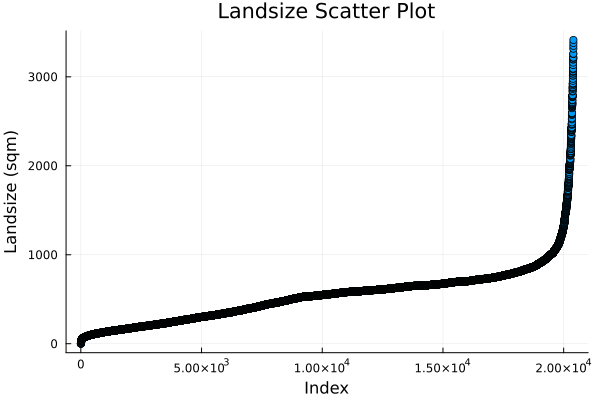

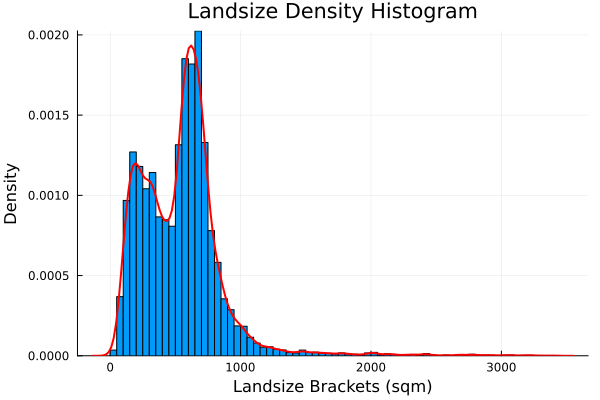

In [81]:
landsize_df = select(df, :Landsize)
filter!(row -> row.Landsize != 0.0, landsize_df)  # Remove rows where Distance is 0 (missing)
sort!(landsize_df, :Landsize)

summary_landsize = summarystats(landsize_df.Landsize)
println("Landsize summary statistics (filtered):")
println(summary_landsize)

# Landsize has extremely large outliers making plots hard to read
# Filter out top 1% of landsize values for better visualisation
filter!(row -> row.Landsize <= quantile(landsize_df.Landsize, 0.99), landsize_df)

summary_landsize_filtered = summarystats(landsize_df.Landsize)
println("Landsize summary statistics (filtered):")
println(summary_landsize_filtered)

scatter(1:length(landsize_df.Landsize), landsize_df.Landsize,
    title = "Landsize Scatter Plot",
    xlabel = "Index",
    ylabel = "Landsize (sqm)",
    legend = false)
savefig("task1_outputs/landsize_scatter_plot.png")
display(plot!())

histogram(landsize_df.Landsize, bins = :auto,
    title = "Landsize Density Histogram",
    xlabel = "Landsize Brackets (sqm)",
    ylabel = "Density",
    legend = false,
    normed = true)
density!(landsize_df.Landsize, lw=2, lc=:red)
savefig("task1_outputs/landsize_density_histogram.png")
display(plot!())



**Visual analysis:**
- Some extreme outliers making visual analysis difficult
Effects of filtering out top 1% of landsize values:
    - 207 data points removed
    - Mean decreased from 664 to 539
    - Standard deviation decreased from 3588 to 323
    - Maximum decreased from 433014 to 3414
    - Plots are now readable

- Logarithmic or polynomial transformation may be appropriate

*Query on dataset: Why are there more bedrooms reported than number of rooms. Maximum # rooms is 15 whereas maximum # bedrooms is 30?*

## Task 2 Exploratory data analysis comparing variables

Create several plots that present the house price as a function of one or more other variables, e.g. distance to the city, house/land size, rooms, car ports, etc. . In presenting these plots, visually search for relationships between variables.

*Assume no trasnformations to be applied yet*

### Price vs Rooms

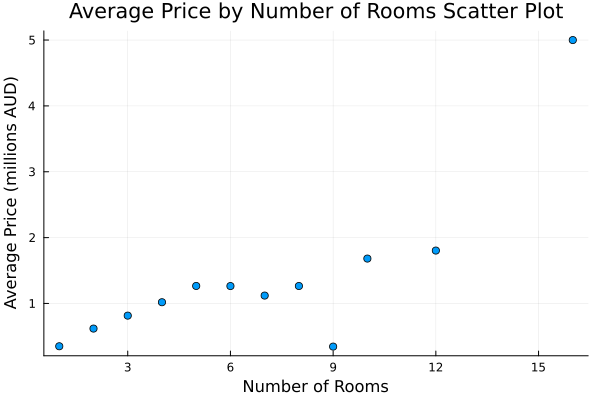

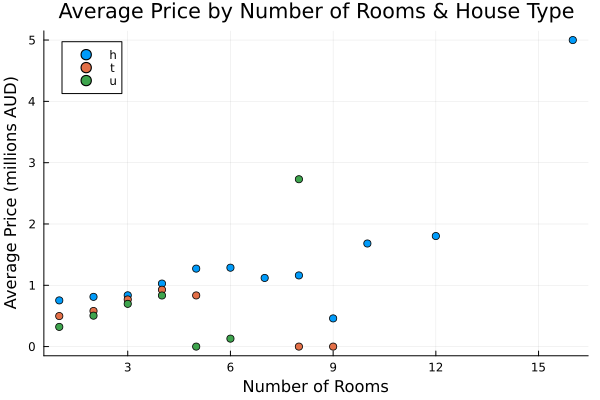

In [82]:
# Scatterplot of Avg Price vs Rooms
rooms_df = groupby(df, :Rooms)
price_by_rooms = combine(rooms_df, :Price => mean ∘ skipmissing => :Avg_Price)
sort!(price_by_rooms, :Rooms)
scatter(price_by_rooms.Rooms, price_by_rooms.Avg_Price,
    title = "Average Price by Number of Rooms Scatter Plot",
    xlabel = "Number of Rooms",
    ylabel = "Average Price (millions AUD)",
    legend = false,
    markersize = 4)
savefig("task2_outputs/single_variables/price_by_rooms_scatter.png")
display(plot!())

# Scatterplot of Avg Price vs Rooms, grouped by Type
rooms_type_df = groupby(df, [:Rooms, :Type])
price_by_rooms_type = combine(groupby(df, [:Rooms, :Type]), :Price => mean ∘ skipmissing => :Avg_Price)
sort!(price_by_rooms_type, [:Type, :Rooms])
scatter(price_by_rooms_type.Rooms, price_by_rooms_type.Avg_Price,
    group = price_by_rooms_type.Type,
    title = "Average Price by Number of Rooms & House Type",
    xlabel = "Number of Rooms",
    ylabel = "Average Price (millions AUD)",
    legend = true,
    markersize = 4)
savefig("task2_outputs/multiple_variables/price_by_rooms_by_type_scatter.png")
display(plot!())

### Price vs Type

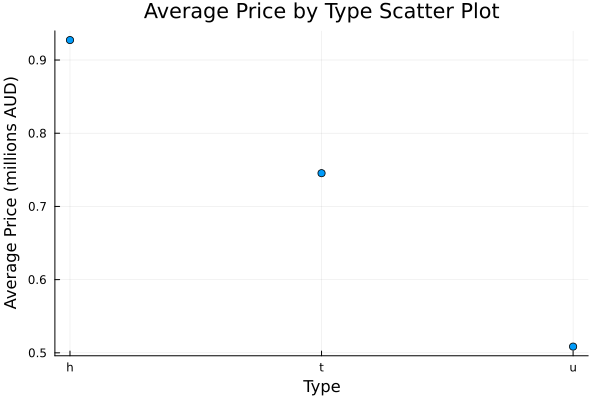

In [83]:
type_df = groupby(df, :Type)
price_by_type = combine(type_df, :Price => mean ∘ skipmissing => :Avg_Price)
sort!(price_by_type, :Type)
scatter(price_by_type.Type, price_by_type.Avg_Price,
    title = "Average Price by Type Scatter Plot",
    xlabel = "Type",
    ylabel = "Average Price (millions AUD)",
    legend = false,
    markersize = 4)
savefig("task2_outputs/single_variables/price_by_type_scatter.png")
display(plot!())

### Price vs Suburb

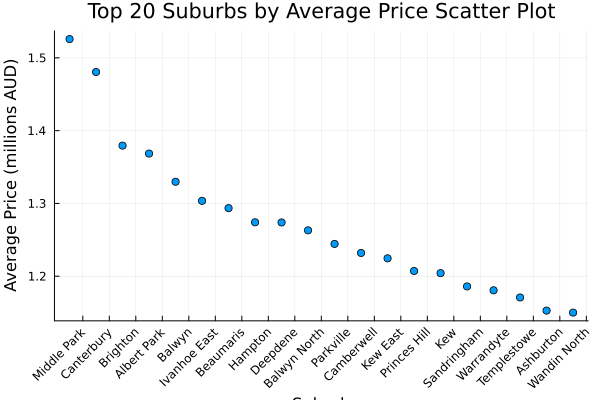

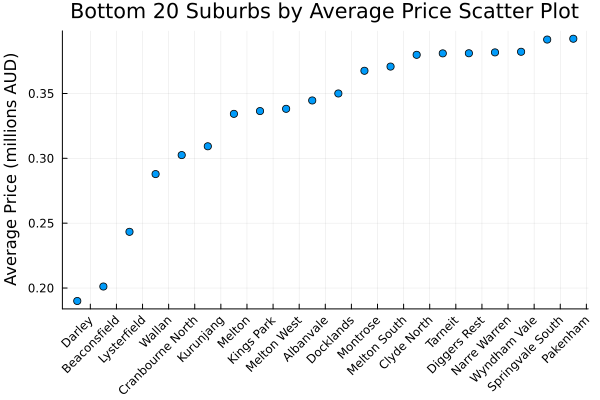

In [84]:
suburbs_df = groupby(df, :Suburb)
price_by_suburb = combine(suburbs_df, :Price => mean ∘ skipmissing => :Avg_Price)
filter!(row -> row.Avg_Price != 0.0, price_by_suburb)  # Remove rows where Avg_Price is 0 (missing)
sort!(price_by_suburb, :Suburb)

# Top 20 suburbs by average price
top20_suburbs = first(sort(price_by_suburb, :Avg_Price, rev=true), 20)
scatter(top20_suburbs.Suburb, top20_suburbs.Avg_Price,
    title = "Top 20 Suburbs by Average Price Scatter Plot",
    xlabel = "Suburb",
    ylabel = "Average Price (millions AUD)",
    legend = false,
    markersize = 4,
    xticks = (1:20, top20_suburbs.Suburb),
    xrotation = 45)
savefig("task2_outputs/single_variables/price_by_suburb(top20)_scatter.png")
display(plot!())

# Bottom 20 suburbs by average price
bottom20_suburbs = first(sort(price_by_suburb, :Avg_Price, rev=false), 20)
scatter(bottom20_suburbs.Suburb, bottom20_suburbs.Avg_Price,
    title = "Bottom 20 Suburbs by Average Price Scatter Plot",
    xlabel = "Suburb",
    ylabel = "Average Price (millions AUD)",
    legend = false,
    markersize = 4,
    xticks = (1:20, bottom20_suburbs.Suburb),
    xrotation = 45)
savefig("task2_outputs/single_variables/price_by_suburb(bottom20)_scatter.png")
display(plot!())

### Price vs Distance

**Hypothesis:** Inverse relationship between distance and price

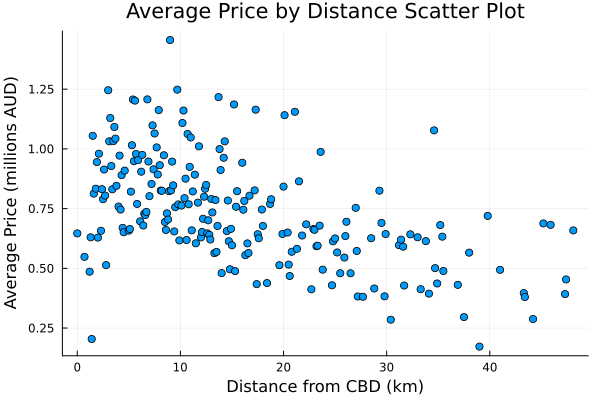

In [85]:
distance_df = groupby(df, :Distance)
price_by_distance = combine(distance_df, :Price => mean ∘ skipmissing => :Avg_Price)
filter!(row -> row.Avg_Price != 0.0, price_by_distance)  # Remove rows where Avg_Price is 0 (missing)
sort!(price_by_distance, :Distance)
scatter(price_by_distance.Distance, price_by_distance.Avg_Price,
    title = "Average Price by Distance Scatter Plot",
    xlabel = "Distance from CBD (km)",
    ylabel = "Average Price (millions AUD)",
    legend = false,
    markersize = 4)
savefig("task2_outputs/single_variables/price_by_distance_scatter.png")
display(plot!())

**Visual analysis:**
- Does display inverse relationship but looks to be quite varied

Want to investigate the relationship between suburb and prices accounting for distance

### Price vs Bedrooms

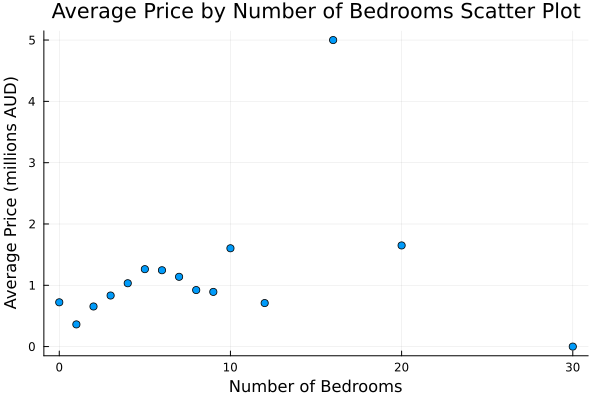

In [86]:
bedroom_df = groupby(df, :Bedroom2)
price_by_bedroom = combine(bedroom_df, :Price => mean ∘ skipmissing => :Avg_Price)
sort!(price_by_bedroom, :Bedroom2) 
scatter(price_by_bedroom.Bedroom2, price_by_bedroom.Avg_Price,
    title = "Average Price by Number of Bedrooms Scatter Plot",
    xlabel = "Number of Bedrooms",
    ylabel = "Average Price (millions AUD)",
    legend = false,
    markersize = 4)
savefig("task2_outputs/single_variables/price_by_bedroom_scatter.png")
display(plot!())

### Price vs Bathrooms

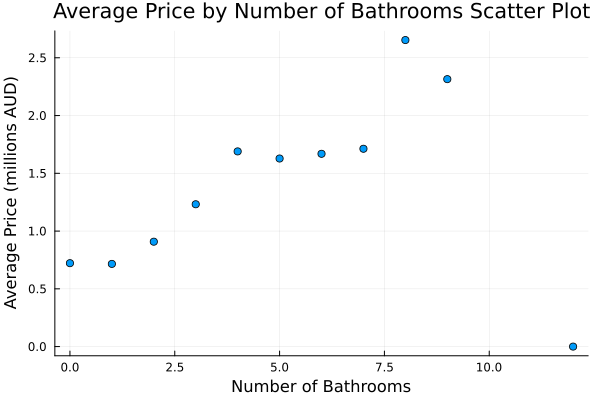

In [87]:
bathroom_df = groupby(df, :Bathroom)
price_by_bathroom = combine(bathroom_df, :Price => mean ∘ skipmissing => :Avg_Price)
sort!(price_by_bathroom, :Bathroom)
scatter(price_by_bathroom.Bathroom, price_by_bathroom.Avg_Price,
    title = "Average Price by Number of Bathrooms Scatter Plot",
    xlabel = "Number of Bathrooms",
    ylabel = "Average Price (millions AUD)",
    legend = false,
    markersize = 4)
savefig("task2_outputs/single_variables/price_by_bathroom_scatter.png")
display(plot!())

### Price vs Car

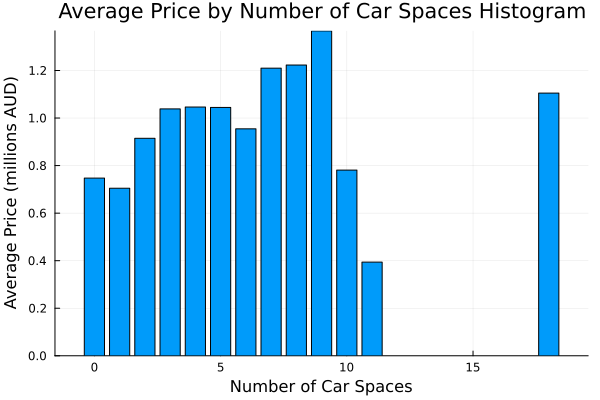

In [88]:
car_df = groupby(df, :Car)
price_by_car = combine(car_df, :Price => mean ∘ skipmissing => :Avg_Price)
sort!(price_by_car, :Car)
filter!(row -> row.Avg_Price != 0, price_by_car)  # Remove rows where Car is 0 (missing)
bar(price_by_car.Car, price_by_car.Avg_Price, 
    bins = minimum(price_by_car.Car)-0.5 : 1 : maximum(price_by_car.Car)+0.5,
    title = "Average Price by Number of Car Spaces Histogram",
    xlabel = "Number of Car Spaces",
    ylabel = "Average Price (millions AUD)",
    legend = false)
savefig("task2_outputs/single_variables/price_by_car_scatter.png")
display(plot!())

**Visual analysis:**

- Does not seem to be any clear correlation between price and number of carparks
- Suggests car spaces can be used as an instrumental variable for the endogenous variables such as distance
- This accounts for the increased demand of car spaces in homes further away from the city which is reflected in factors such as landsize as well

### Price vs Landsize

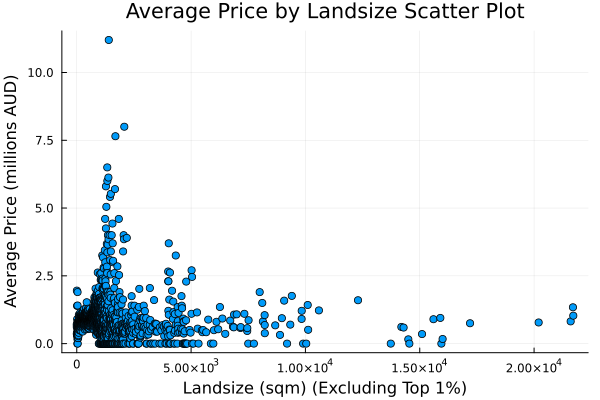

In [89]:
landsize_df = groupby(df, :Landsize)
price_by_landsize = combine(landsize_df, :Price => mean ∘ skipmissing => :Avg_Price)
sort!(price_by_landsize, :Landsize)
# Landsize has extremely large outliers making plots hard to read
# Filter out top 1% of landsize values for better visualisation
filter!(row -> row.Landsize <= quantile(price_by_landsize.Landsize, 0.99), price_by_landsize)

scatter(price_by_landsize.Landsize, price_by_landsize.Avg_Price,
    title = "Average Price by Landsize Scatter Plot",
    xlabel = "Landsize (sqm) (Excluding Top 1%)",
    ylabel = "Average Price (millions AUD)",
    legend = false,
    markersize = 4)
savefig("task2_outputs/single_variables/price_by_landsize_scatter.png")
display(plot!())


### Price vs YearBuilt

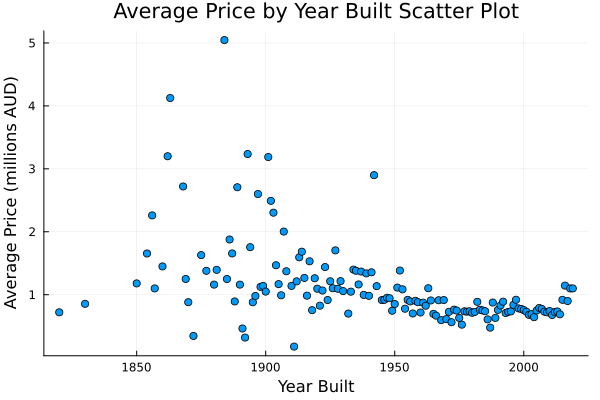

In [90]:
yearbuilt_df = groupby(df, :YearBuilt)
price_by_yearbuilt = combine(yearbuilt_df, :Price => mean ∘ skipmissing => :Avg_Price)
filter!(row -> row.YearBuilt > 1800, price_by_yearbuilt)  # Remove homes built before 1800 (accounts for missing variables and uncommon outliers)
filter!(row -> row.Avg_Price != 0.0, price_by_yearbuilt)  # Remove rows where Avg_Price is 0 (missing)
sort!(price_by_yearbuilt, :YearBuilt)
scatter(price_by_yearbuilt.YearBuilt, price_by_yearbuilt.Avg_Price,
    title = "Average Price by Year Built Scatter Plot",
    xlabel = "Year Built",
    ylabel = "Average Price (millions AUD)",
    legend = false,
    markersize = 4)
savefig("task2_outputs/single_variables/price_by_yearbuilt_scatter.png")
display(plot!())

### Price vs Age when Sold
The age of the house when sold is a better reflection of how the year built affects price

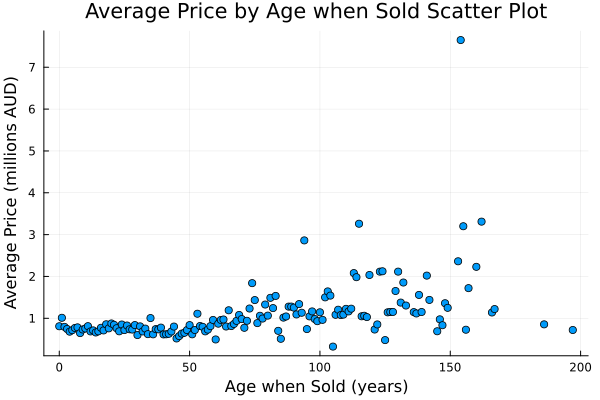

In [101]:
age_df = groupby(df, :Age)
price_by_age = combine(age_df, :Price => mean ∘ skipmissing => :Avg_Price)
filter!(row -> row.Avg_Price != 0.0, price_by_age)  # Remove rows where Avg_Price is 0 (missing)
filter!(row -> row.Age < 200, price_by_age)  # Remove rows when houses over 200 years old are sold
sort!(price_by_age, :Age)
scatter(price_by_age.Age, price_by_age.Avg_Price,
    title = "Average Price by Age when Sold Scatter Plot",
    xlabel = "Age when Sold (years)",
    ylabel = "Average Price (millions AUD)",
    legend = false,
    markersize = 4)
savefig("task2_outputs/single_variables/price_by_age_scatter.png")
display(plot!())

## Task 3 Exploratory data analysis over time
Create several plots that visualize trends in the data over time. Specifically plot the total transaction amount, the number of sales, and the fraction of sales which were houses (`Type = "h"`). You may aggregate values into months.

In [104]:
# First group by year and months
time_df = groupby(df, [:Year, :Month]);

### Total Transaction Amount over Time

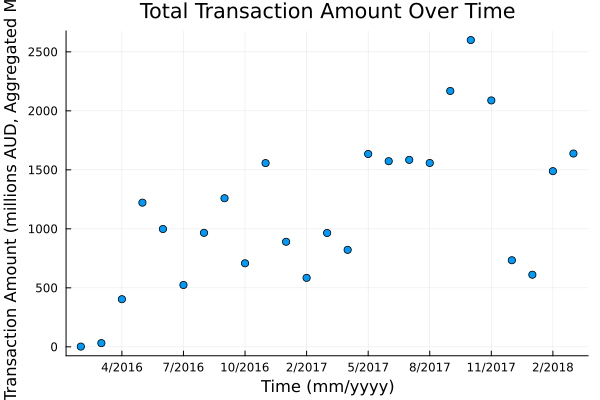

In [106]:
transaction_amt_over_time = combine(time_df, :Price => sum => :Total_Transaction_Amount)
transform!(transaction_amt_over_time, [:Year, :Month] => ByRow((y,m) -> string(m) * "/" * string(y)) => :Period)

sort!(transaction_amt_over_time, [:Year, :Month])
scatter(transaction_amt_over_time.Period, transaction_amt_over_time.Total_Transaction_Amount,
    title = "Total Transaction Amount Over Time",
    xlabel = "Time (mm/yyyy)",
    ylabel = "Total Transaction Amount (millions AUD, Aggregated Monthly)",
    legend = false)
savefig("task3_outputs/total_transaction_amount_over_time.png")
display(plot!())

### Number of Sales over Time

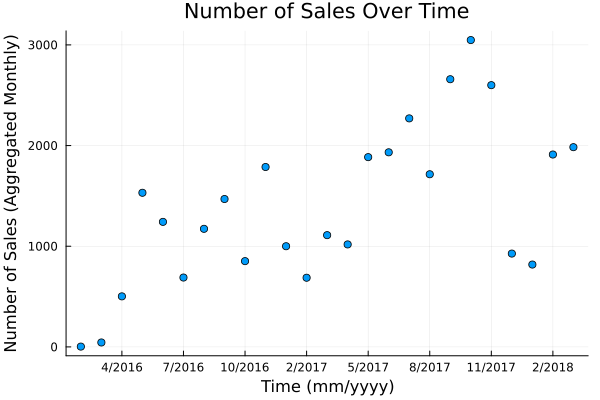

In [108]:
num_sales = combine(time_df, nrow => :Number_of_Sales)
transform!(num_sales, [:Year, :Month] => ByRow((y,m) -> string(m) * "/" * string(y)) => :Period)
sort!(num_sales, [:Year, :Month])
scatter(num_sales.Period, num_sales.Number_of_Sales,
    title = "Number of Sales Over Time",
    xlabel = "Time (mm/yyyy)",
    ylabel = "Number of Sales (Aggregated Monthly)",
    legend = false)
savefig("task3_outputs/number_of_sales_over_time.png")
display(plot!())

### Sales data by Type

#### Number of Sales by Type

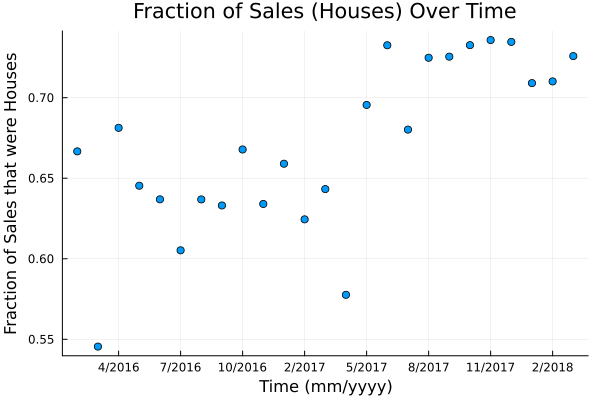

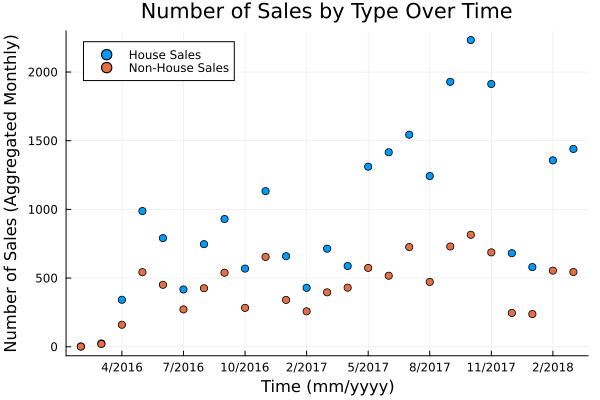

In [118]:
sales_by_type = combine(time_df, 
    :Type => (x -> sum(x .== "h")) => :House_Sales,
    :Type => (x -> sum(x .!= "h")) => :Non_House_Sales)
transform!(sales_by_type, [:Year, :Month] => ByRow((y,m) -> string(m) * "/" * string(y)) => :Period)
sort!(sales_by_type, [:Year, :Month]);

sales_by_type.Fraction_Houses = sales_by_type.House_Sales ./ (sales_by_type.House_Sales .+ sales_by_type.Non_House_Sales);

# Fraction of sales that were houses over time
scatter(sales_by_type.Period, sales_by_type.Fraction_Houses,
    title = "Fraction of Sales (Houses) Over Time",
    xlabel = "Time (mm/yyyy)",
    ylabel = "Fraction of Sales that were Houses",
    legend = false)
savefig("task3_outputs/fraction_of_houses_over_time.png")
display(plot!())

# Fraction of sales per type over time
scatter(sales_by_type.Period, sales_by_type.House_Sales,
    label = "House Sales",
    title = "Number of Sales by Type Over Time",
    xlabel = "Time (mm/yyyy)",
    ylabel = "Number of Sales (Aggregated Monthly)")
scatter!(sales_by_type.Period, sales_by_type.Non_House_Sales,
    label = "Non-House Sales")
savefig("task3_outputs/number_of_sales_by_type_over_time.png") 
display(plot!())

#### Aggregated transaction amount by type

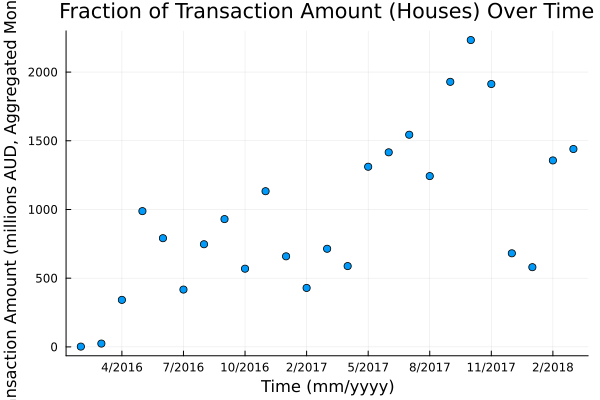

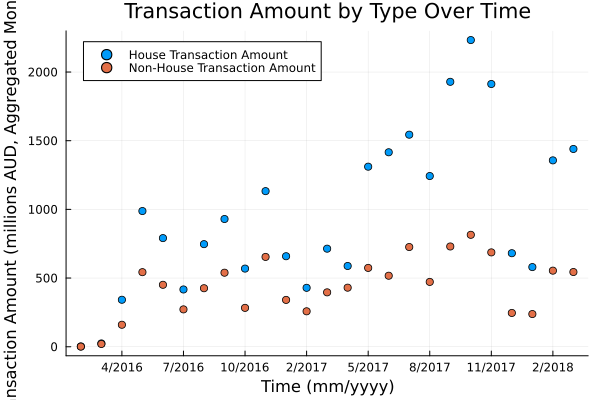

In [123]:
transaction_by_type = combine(time_df, 
    :Type => (x -> sum(x .== "h")) => :House_Transaction_Amount,
    :Type => (x -> sum(x .!= "h")) => :Non_House_Transaction_Amount)
transform!(transaction_by_type, [:Year, :Month] => ByRow((y,m) -> string(m) * "/" * string(y)) => :Period)
sort!(transaction_by_type, [:Year, :Month]);

transaction_by_type.Fraction_Houses = transaction_by_type.House_Transaction_Amount ./ (transaction_by_type.House_Transaction_Amount .+ transaction_by_type.Non_House_Transaction_Amount);

# Fraction of transaction amount that were houses over time
scatter(transaction_by_type.Period, transaction_by_type.House_Transaction_Amount,
    title = "Fraction of Transaction Amount (Houses) Over Time",
    xlabel = "Time (mm/yyyy)",
    ylabel = "Transaction Amount (millions AUD, Aggregated Monthly)",
    legend = false)
savefig("task3_outputs/transaction_amount_houses_over_time.png")
display(plot!())

# Fraction of transaction amount per type over time
scatter(transaction_by_type.Period, transaction_by_type.House_Transaction_Amount,
    label = "House Transaction Amount",
    title = "Transaction Amount by Type Over Time",
    xlabel = "Time (mm/yyyy)",
    ylabel = "Transaction Amount (millions AUD, Aggregated Monthly)")
scatter!(transaction_by_type.Period, transaction_by_type.Non_House_Transaction_Amount,
    label = "Non-House Transaction Amount")
savefig("task3_outputs/transaction_amount_by_type_over_time.png")
display(plot!())

## Task 4 Linear Regression Models
Review your results of Task 2 and try to fit several linear regression models for predicting house price as a function of variables. Use GLM.jl. See usage examples from Chapter 8 of Statistics with Julia or from elsewhere. (Loosely) asses the quality of the linear regression models either via p-values from the statistical output of the models, or by breaking up the data into a training set and validation set. Determine a linear regression model which you find good for predicting house prices. If you believe variable transformations are needed, carry these out.

### GLM: Price vs Rooms

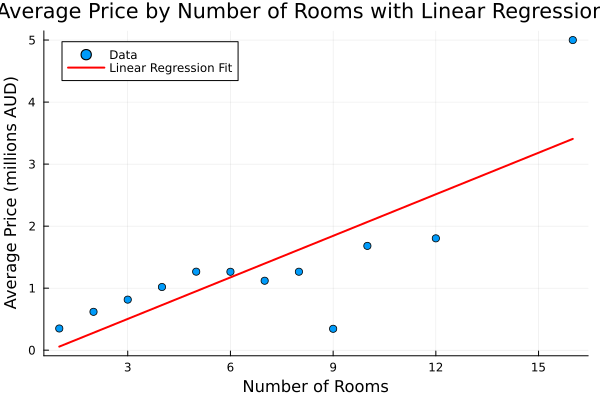

In [124]:
model = lm(@formula(Avg_Price ~ Rooms), price_by_rooms)
scatter(price_by_rooms.Rooms, price_by_rooms.Avg_Price,
    title = "Average Price by Number of Rooms with Linear Regression Fit",
    xlabel = "Number of Rooms",
    ylabel = "Average Price (millions AUD)",
    label = "Data")
plot!(price_by_rooms.Rooms, predict(model), lw=2, lc=:red, label="Linear Regression Fit")
savefig("task4_outputs/price_by_rooms_linear_regression.png")
display(plot!())

Would like to include bathrooms and bedrooms overlaying this on a different axis

### GLM Price vs Age
*Excludes the outlier sold at around 800 years old*

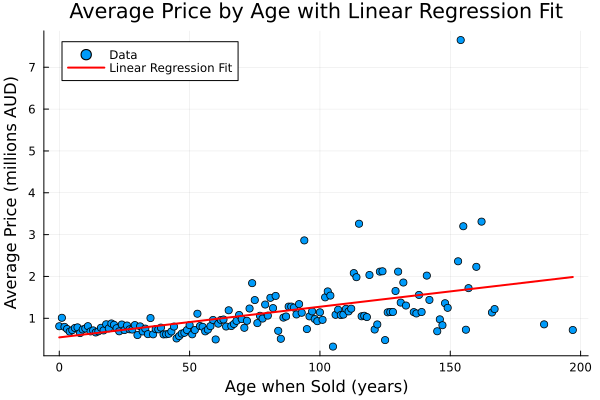

In [125]:
model = lm(@formula(Avg_Price ~ Age), price_by_age)
scatter(price_by_age.Age, price_by_age.Avg_Price,
    title = "Average Price by Age with Linear Regression Fit",
    xlabel = "Age when Sold (years)",
    ylabel = "Average Price (millions AUD)",
    label = "Data")
plot!(price_by_age.Age, predict(model), lw=2, lc=:red, label="Linear Regression Fit")
savefig("task4_outputs/price_by_age_linear_regression.png")
display(plot!())

### GLM Price vs Distance

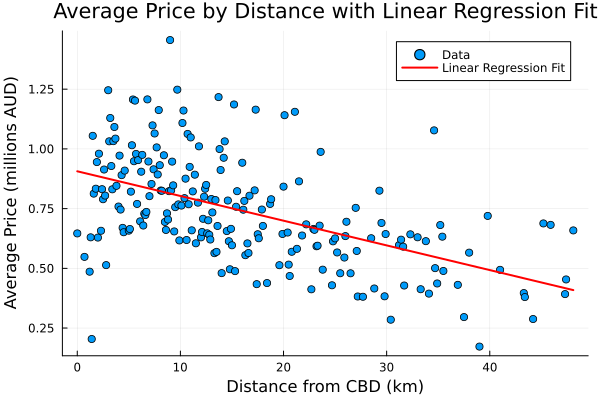

In [126]:
model = lm(@formula(Avg_Price ~ Distance), price_by_distance)

scatter(price_by_distance.Distance, price_by_distance.Avg_Price,
    title = "Average Price by Distance with Linear Regression Fit",
    xlabel = "Distance from CBD (km)",
    ylabel = "Average Price (millions AUD)",
    label = "Data")
plot!(price_by_distance.Distance, predict(model), lw=2, lc=:red, label="Linear Regression Fit")
savefig("task4_outputs/price_by_distance_linear_regression.png")
display(plot!())

Include `car` as an instrumental variable because demand for houses with car ports is higher when distance is higher which could cause some kind of endogenous bias.

### GLM Price by Landsize

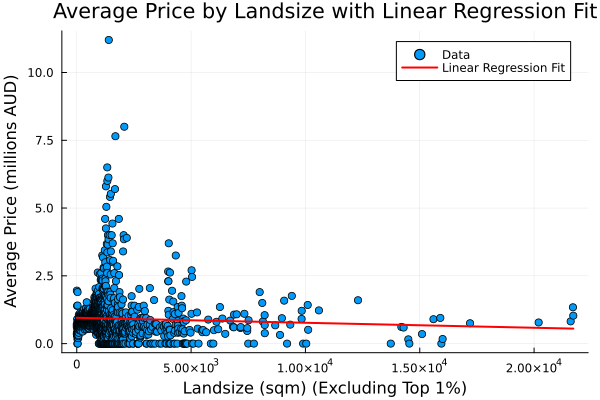

In [128]:
model = lm(@formula(Avg_Price ~ Landsize), price_by_landsize)
scatter(price_by_landsize.Landsize, price_by_landsize.Avg_Price,
    title = "Average Price by Landsize with Linear Regression Fit",
    xlabel = "Landsize (sqm) (Excluding Top 1%)",
    ylabel = "Average Price (millions AUD)",
    label = "Data")
plot!(price_by_landsize.Landsize, predict(model), lw=2, lc=:red, label="Linear Regression Fit")
savefig("task4_outputs/price_by_landsize_linear_regression.png")
display(plot!())

### Multiple Linear Regression
Linear regression model that accounts for variables distance, landsize, number of rooms, age, and type.

In future would like to create multiple of these to find which has the lowest p-value without adding variables that have high correlation with each other (such as number of rooms and number of bedrooms). 

Transformations should also be applied to all noted in the visual analyses in task1.

## Task 5

Would use longitude and latitude variables to find points on map. Shapes to represent house sale (may need to aggregate in densely populated areas)

- Use a colour shading scale to represent price of sale - darkest to represent most expensive, lighter to represent least expensive with legend on the side.
- Use different colours for different types (e.g. red for houses, yellow for units, etc)
- Use diffreent shapes for some kind of instrumental variable (such as carport: Yes/No)
- Possibly change size to represent landsize although if aggregating sales for densely populated regions changing the size would be used to represent number of sales in that region (possibly grouped by suburbs with the shape placed as according to the spread of longitudes and latitudes of sales in that suburb (taking the mean of both to find the most desnely sold house area point in that suburb))